# Table of Contents

- [1. Gravimetric Modeling](#1-gravimetric-modeling)
  - [1.1 Importing Packages](#11-importing-packages)
  - [1.2 Forward Modeling](#12-forward-modeling)
  - [1.3 Synthetic Models from Article](#13-synthetic-models-from-article)
    - [1.3.1 Modeling Prism Parameters](#131-modeling-prism-parameters)
    - [1.3.2 Forward Modeling: 200 Vertical Prisms Mesh](#132-forward-modeling-200-vertical-prisms-mesh)
    - [1.3.3 Dip Angle Variation Cases](#133-dip-angle-variation-cases)
      - [1.3.3.1 45 Degrees](#1331-45-degrees)
      - [1.3.3.2 60 Degrees](#1332-60-degrees)
      - [1.3.3.3 75 Degrees](#1333-75-degrees)
      - [1.3.3.4 90 Degrees](#1334-90-degrees)
      - [1.3.3.5 105 Degrees](#1335-105-degrees)
      - [1.3.3.6 All Curves](#1336-all-curves)
    - [1.3.4 Horizontal Displacement of Contact](#134-horizontal-displacement-of-contact)
      - [1.3.4.1 Model 1 (0.1 km)](#1341-model-1-01-km)
      - [1.3.4.2 Model 2 (0.3 km)](#1342-model-2-03-km)
      - [1.3.4.3 Model 3 (0.5 km)](#1343-model-3-05-km)
      - [1.3.4.4 Model 4 (0.7 km)](#1344-model-4-07-km)
      - [1.3.4.5 Model 5 (0.9 km)](#1345-model-5-09-km)
      - [1.3.4.6 All Curves](#1346-all-curves)
    - [1.3.5 Vertical Displacement of Contact](#135-vertical-displacement-of-contact)
      - [1.3.5.1 Model 1 (0.1 km)](#1351-model-1-01-km)
      - [1.3.5.2 Model 2 (0.3 km)](#1352-model-2-03-km)
      - [1.3.5.3 Model 3 (0.5 km)](#1353-model-3-05-km)
      - [1.3.5.4 Model 4 (0.7 km)](#1354-model-4-07-km)
      - [1.3.5.5 Model 5 (0.9 km)](#1355-model-5-09-km)
      - [1.3.5.6 All Curves](#1356-all-curves)
  


# Gravimetric Modeling

### Importing Packages

In [38]:
import numpy as np
import random
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import matplotlib.patches as patches
import math
import cmath 
from decimal import Decimal
import sympy as sp 
from matplotlib.patches import Circle

import sys
np.set_printoptions(
                   edgeitems=10, linewidth=50)


## Foward Modeling

#### Modeling Prism Parameters

In [39]:
# --------------------------------------------
# SYNTHETIC DATA (FIELD SIMULATION)
# --------------------------------------------

# Measurement station positions (in km)
vecx = [0.05, 0.15, 0.25, 0.35, 0.45, 0.55, 0.65, 0.75, 0.85, 0.95,
        1.05, 1.15, 1.25, 1.35, 1.45, 1.55, 1.65, 1.75, 1.85, 1.95]

# Subset of positions for plotting
vecx_plotagem = [0.05, 0.15, 0.25, 0.35, 0.45, 0.55, 0.65, 0.75, 0.85, 0.95, 1.05]

# Universal gravitational constant 
G = 6.67430 # 6.67430* 1e-11 * 1e11(mGal)

# Layer depths: top and base of each vertical prism (in km)
z1 = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
z2 = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

# Horizontal positions of the prisms (in km)
xq = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9,
      1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9]

# Prism width (in km)
t = 0.1

# Modeling parameters
porcentagem_erro = 0         # error percentage (used for synthetic noise)
largura_total = 1            # total model width (in km)
profundidade_total = 1       # total model depth (in km)

# Note: all arctangent values are expected in radians


### Foward Modeling: 200 Vertical Prisms Mesh

In [40]:
def gvertical(vecx, R, xq, z1, z2, t):

    gz = np.zeros(len(vecx), dtype=float)

    # Safe evaluation of the logarithmic term
    def safe_log(vecx, xq, z1, z2, t, i):

        # First logarithmic term
        try:
            ln1 = math.log(
                (z2**2 + (vecx[i]-xq)**2) /
                (z1**2 + (vecx[i]-xq)**2)
            )
        except (ValueError, ZeroDivisionError, OverflowError):
            ln1 = 0.0

        # Second logarithmic term
        try:
            ln2 = math.log(
                (z1**2 + ((vecx[i]-xq)-t)**2) /
                (z2**2 + ((vecx[i]-xq)-t)**2)
            )
        except (ValueError, ZeroDivisionError, OverflowError):
            ln2 = 0.0

        return ln1, ln2
    

    def safe_atan(vecx, xq, z1, z2, t, i):

        # First arctangent
        try:
            atan1 = math.atan(((vecx[i]-xq)-t)/z2)
        except (ValueError, ZeroDivisionError, OverflowError):
            atan1 = 0.0

        # Second arctangent
        try:
            atan2 = math.atan((vecx[i]-xq)/z2)
        except (ValueError, ZeroDivisionError, OverflowError):
            atan2 = 0.0

        # Third arctangent
        try:
            atan3 = math.atan(((vecx[i]-xq)-t)/z1)
        except (ValueError, ZeroDivisionError, OverflowError):
            atan3 = 0.0

        # Fourth arctangent
        try:
            atan4 = math.atan((vecx[i]-xq)/z1)
        except (ValueError, ZeroDivisionError, OverflowError):
            atan4 = 0.0

        return atan1, atan2, atan3, atan4


    for i in range(len(gz)):

        ln1, ln2 = safe_log(vecx, xq, z1, z2, t, i)

        atan1, atan2, atan3, atan4 = safe_atan(vecx, xq, z1, z2, t, i)

        gz[i] = (2*G*R) * (
            ((vecx[i]-xq)/2) * ln1 +
            (((vecx[i]-xq)-t)/2) * ln2 -
            z2 * ( atan1 - atan2) +
            z1 * ( atan3 - atan4 )
        )
    return gz


In [41]:
def automatic_gv_curve(densidades, vecx, xq, z1, z2, t_size):
    final_curve = np.zeros(len(vecx), dtype=float)
    prisms_by_layer = len(xq) 
    counter = 0 
    
    for d in densidades:
        for i, j in enumerate(d):
            idx_camada = counter // prisms_by_layer
            if idx_camada >= len(z1):
                break
            final_curve += gvertical(vecx, j, xq[i], z1[idx_camada], z2[idx_camada], t_size)
            counter += 1

    return final_curve 

 Sensitivity Syntetic Models

A total of 15 synthetic gravimetric models were analyzed, organized into three groups of five, each addressing a specific aspect of the study. The first group focused on horizontal contact displacement models, evaluating displacement values of 0.1 km, 0.3 km, 0.5 km, 0.7 km, and 0.9 km. The second group investigated vertical displacement models, applying the same set of displacement values. Finally, the third group examined dip angular variation models, considering angles of 45°, 60°, 75°, 90°, and 105°.

####  Dip Angle Variation Cases

#### 45 Degrees

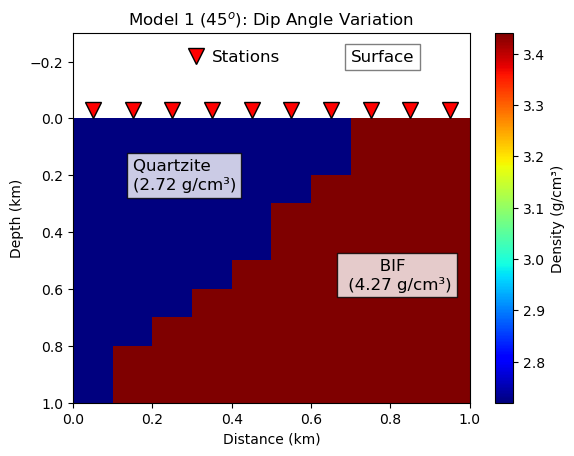

In [42]:
# Define a 10x20 grid of density values in g/cm³ (converted later to kg/m³)
densities = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0]
])

# Reference density model in g/cm³ for plotting (10x10 grid)
model_densities = np.array([
    [2.72,2.72,2.72,2.72,2.72, 2.72,2.72,3.44, 3.44, 3.44],
    [2.72,2.72,2.72,2.72,2.72, 2.72,2.72,3.44, 3.44, 3.44],
    [2.72,2.72,2.72,2.72,2.72, 2.72,3.44, 3.44, 3.44, 3.44],
    [2.72,2.72,2.72,2.72,2.72, 3.44,3.44, 3.44, 3.44, 3.44],
    [2.72,2.72,2.72,2.72,2.72, 3.44,3.44, 3.44, 3.44, 3.44],
    [2.72,2.72,2.72,2.72,3.44, 3.44,3.44, 3.44, 3.44, 3.44],
    [2.72,2.72,2.72,3.44,3.44, 3.44,3.44, 3.44, 3.44, 3.44],
    [2.72,2.72,3.44,3.44,3.44, 3.44,3.44, 3.44, 3.44, 3.44],
    [2.72,3.44,3.44,3.44,3.44, 3.44,3.44, 3.44, 3.44, 3.44],
    [2.72,3.44,3.44,3.44,3.44, 3.44,3.44, 3.44, 3.44, 3.44]
])



# Plotting the initial 2D density model
plt.imshow(model_densities, extent=[0, 1, 1, 0], aspect='auto', cmap='jet')
plt.ylim((1, -0.3))  # Invert Y-axis for depth

# Plot measurement station markers (red inverted triangles)
vecxx = np.array([0.05,0.15,0.25,0.35,0.45,0.55,0.65,0.75,0.85,0.95])
vecyy = np.zeros_like(vecxx) - 0.03
plt.plot(vecxx, vecyy, "v", markersize=12, color='red', markeredgecolor='black')

# Add annotation labels
plt.text(0.7, -0.2, 'Surface', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))
plt.text(0.35, -0.2, 'Stations', fontsize=12)
plt.plot(0.31, -0.22, "v", markersize=11, color='red', markeredgecolor='black')
plt.text(0.15, 0.25, 'Quartzite \n(2.72 g/cm³)', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))
plt.text(0.68, 0.60, '       BIF \n (4.27 g/cm³)', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))

# Colorbar and axis labels
plt.colorbar(label='Density (g/cm³)')
plt.xlabel('Distance (km)')
plt.ylabel('Depth (km)')
plt.title('Model 1 (45$^o$): Dip Angle Variation')

# Save figure
# plt.savefig("DAV-1.png", facecolor='w', bbox_inches="tight", transparent=False, dpi=300)
plt.show()


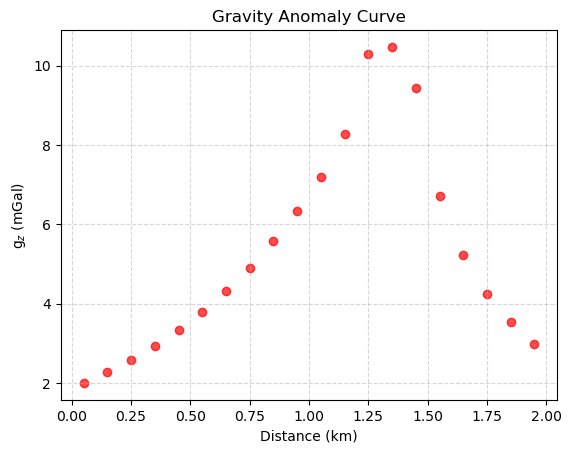

In [43]:
# Generate the gravity anomaly curve using the defined density model
final_curve1 = automatic_gv_curve(densities, vecx, xq, z1, z2, t)
final_curve1  # This will print the array with the calculated anomaly values

# === Plot the Anomaly Curve ===

# Create a scatter plot of the computed gravity anomaly values
plt.scatter(vecx, final_curve1, color='red', marker='o', alpha=0.7)

# Add axis labels and plot title
plt.xlabel('Distance (km)')
plt.ylabel('g$_z$ (mGal)')
plt.title('Gravity Anomaly Curve')

# Add a dashed grid in the background for readability
plt.grid(True, linestyle='--', alpha=0.5)

# Optional axis limits (uncomment if needed)
# plt.xlim(0.5, 1.2)
# plt.ylim(-0.5, 1.0)

# Optional: add text with noise level
# plt.text(-10, 14, 'Noise: 6%', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))

# Optional: show legend
# plt.legend(loc='upper center')

# Display the plot
plt.show()


#### 60 Degrees

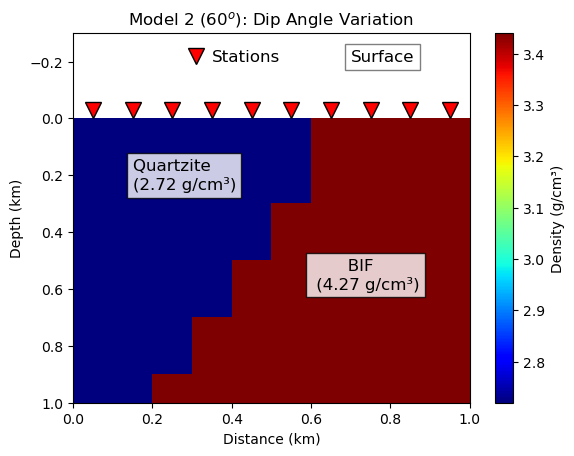

In [44]:
# Define the density contrast model (in 10x20 format) for BIF structure
densities = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0]
])

# Define background model (10x10) with geological units (quartzite and BIF)
model_densities= np.array([
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44]
])

# === PLOT THE 2D MODEL ===
plt.imshow(model_densities, extent=[0, 1, 1, 0], aspect='auto', cmap='jet')
plt.ylim((1, -0.3))  # Invert Y axis to show surface on top

# Add markers for stations as red downward triangles
vecxx = np.array([0.05,0.15,0.25,0.35,0.45,0.55,0.65,0.75,0.85,0.95])
vecyy = np.zeros_like(vecxx) - 0.03
plt.plot(vecxx, vecyy, "v", markersize=12, color='red', markeredgecolor='black')

# Annotate the figure with labels
plt.text(0.7, -0.2, 'Surface', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))
plt.text(0.35, -0.2, 'Stations', fontsize=12)
plt.plot(0.31, -0.22, "v", markersize=11, color='red', markeredgecolor='black')
plt.text(0.15, 0.25, 'Quartzite \n(2.72 g/cm³)', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))
plt.text(0.6, 0.60, '       BIF \n (4.27 g/cm³)', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))

# Optional labels for other rock types (commented out)
# plt.text(0.6, 0.80, 'Limestone \n (2.55 g/cm³)', ...)
# plt.text(0.10, 0.96, 'Metamorphic \n (2.74 g/cm³)', ...)

# Add colorbar, labels and title
plt.colorbar(label='Density (g/cm³)')
plt.xlabel('Distance (km)')
plt.ylabel('Depth (km)')
plt.title('Model 2 (60$^o$): Dip Angle Variation')

# Save figure and display
# plt.savefig("DAV-2.png", facecolor='w', bbox_inches="tight", transparent=False, dpi=300)
plt.show()


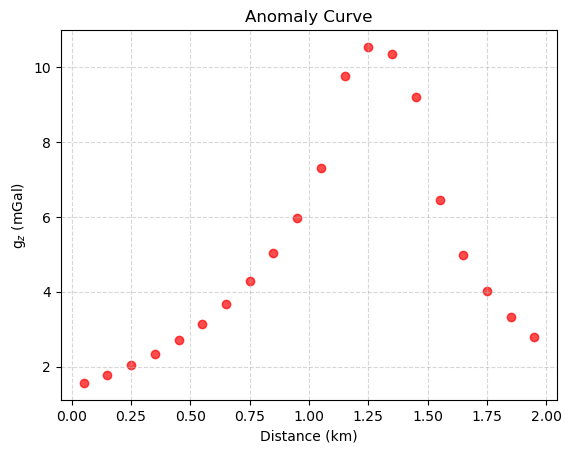

In [45]:
# Compute the gravity anomaly curve for the defined model
final_curve2 = automatic_gv_curve(densities, vecx, xq, z1, z2, t)
final_curve2

# === PLOT THE GRAVITY ANOMALY CURVE ===

# Plot the synthetic gravity anomaly as a scatter plot
plt.scatter(vecx, final_curve2, color='red', marker='o', alpha=0.7)

# Set axis labels and plot title
plt.xlabel('Distance (km)')
plt.ylabel('g$_z$ (mGal)')
plt.title('Anomaly Curve')

# Add background grid for better readability
plt.grid(True, linestyle='--', alpha=0.5)

# Optional: Define custom axis limits
# plt.xlim(-0.25, 1.2)   # X-axis range
# plt.ylim(-0.5, 1.0)    # Y-axis range

# Optional: Add annotation or legend
# plt.text(-10, 14, 'Noise: 6%', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))
# plt.legend(loc='upper center')

# Display the plot
plt.show()


#### 75 Degrees

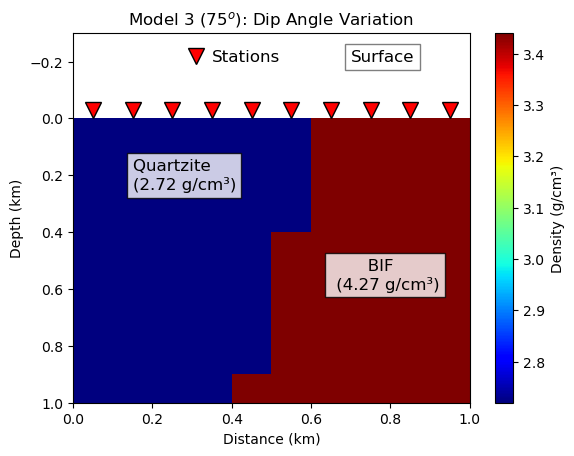

In [46]:
# === DENSITY MODEL (10x20 grid) ===

densities = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0]
])

model_densities= np.array([
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44]
])


# === PLOT THE DENSITY MODEL ===

plt.imshow(model_densities, extent=[0, 1, 1, 0], aspect='auto', cmap='jet')

# Set vertical axis to show depth increasing downward
plt.ylim((1, -0.3))

# Add inverted triangle markers for station locations
vecxx = np.array([0.05,0.15,0.25,0.35,0.45,0.55,0.65,0.75,0.85,0.95])
vecyy = np.zeros_like(vecxx) - 0.03
plt.plot(vecxx, vecyy, "v", markersize=12, color='red', markeredgecolor='black')

# Add annotations for surface, stations, and geological units
plt.text(0.7, -0.2, 'Surface', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))
plt.text(0.35, -0.2, 'Stations', fontsize=12)
plt.plot(0.31, -0.22, "v", markersize=11, color='red', markeredgecolor='black')
plt.text(0.15, 0.25, 'Quartzite \n(2.72 g/cm³)', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))
plt.text(0.65, 0.60, '       BIF \n (4.27 g/cm³)', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))

# Optional: other lithologies
# plt.text(...)

# Add color bar and axis labels
plt.colorbar(label='Density (g/cm³)')
plt.xlabel('Distance (km)')
plt.ylabel('Depth (km)')
plt.title('Model 3 (75$^o$): Dip Angle Variation')

# Save and show the figure
# plt.savefig("DAV-3.png", facecolor='w', bbox_inches="tight", transparent=False, dpi=300)
plt.show()


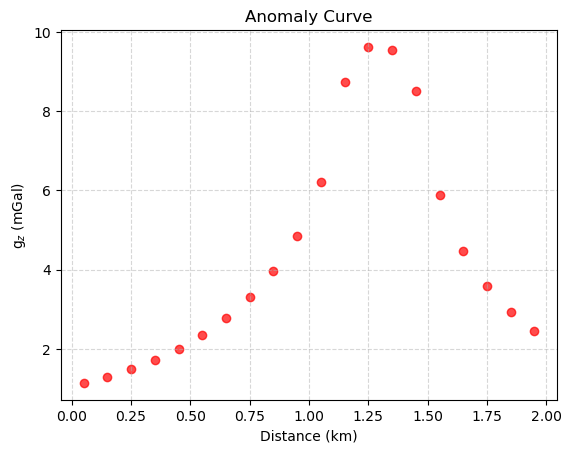

In [47]:
# Compute the Bouguer anomaly curve for Model 3
final_curve3 = automatic_gv_curve(densities, vecx, xq, z1, z2, t)
final_curve3

# PLOT THE GRAPH

# Create a scatter plot for the calculated gravity anomaly
# plt.scatter(vecx, verificar, color='dodgerblue', marker='o', alpha=0.7)
plt.scatter(vecx, final_curve3, color='red', marker='o', alpha=0.7)

# Add axis labels and a title to the plot
plt.xlabel('Distance (km)')
plt.ylabel('g$_z$ (mGal)')
plt.title('Anomaly Curve')

# Add a grid to the background
plt.grid(True, linestyle='--', alpha=0.5)

# Set x and y axis limits if needed
# plt.xlim(-0.25, 1.2)  # X-axis range
# plt.ylim(-0.5, 1)     # Y-axis range

# Add a text box (optional)
# plt.text(-10, 14, 'Noise: 6%', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))

# Show legend (optional)
# plt.legend(loc='upper center')

# Display the plot
plt.show()


#### 90 Degrees

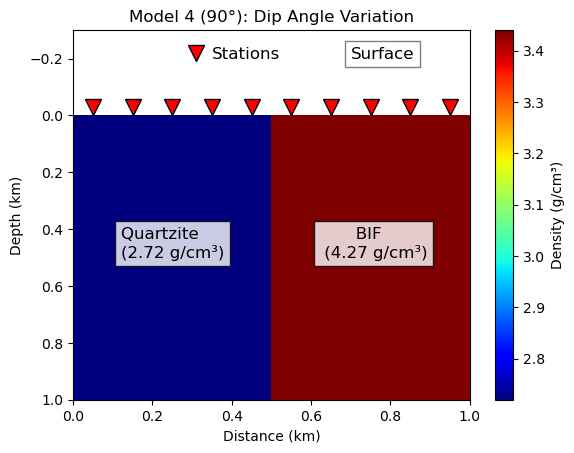

In [48]:
# 10x10 density model for 90° dip

densities = np.array([
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.64, 0.64, 0.64, 0.64, 0.64, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.64, 0.64, 0.64, 0.64, 0.64, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.64, 0.64, 0.64, 0.64, 0.64, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.64, 0.64, 0.64, 0.64, 0.64, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.64, 0.64, 0.64, 0.64, 0.64, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.64, 0.64, 0.64, 0.64, 0.64, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.64, 0.64, 0.64, 0.64, 0.64, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.64, 0.64, 0.64, 0.64, 0.64, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.64, 0.64, 0.64, 0.64, 0.64, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0.64, 0.64, 0.64, 0.64, 0.64, 0, 0, 0, 0, 0],
])

model_densities= np.array([
    [2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44],
])

# Rock types (for reference):
# Clay - 2.21 g/cm³
# Limestone - 2.55 g/cm³
# Sandstone - 2.00 g/cm³
# Conglomerate - 2.50 g/cm³
# Metamorphic - 2.74 g/cm³


##### PLOT MODEL #####

# Plot the 2D geological model with different densities
plt.imshow(model_densities, extent=[0, 1, 1, 0], aspect='auto', cmap='jet')

# Invert Y-axis and adjust scale
plt.ylim((1, -0.3))

# Add markers for stations (inverted triangles)
vecxx = np.array([0.05, 0.15, 0.25, 0.35, 0.45, 0.55, 0.65, 0.75, 0.85, 0.95])
vecyy = np.zeros_like(vecxx) - 0.03
plt.plot(vecxx, vecyy, "v", markersize=12, color='red', markeredgecolor='black')

# Add labels
plt.text(0.7, -0.2, 'Surface', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))
plt.text(0.35, -0.2, 'Stations', fontsize=12)
plt.plot(0.31, -0.22, "v", markersize=11, color='red', markeredgecolor='black')
plt.text(0.12, 0.5, 'Quartzite \n(2.72 g/cm³)', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))
plt.text(0.62, 0.50, '       BIF \n (4.27 g/cm³)', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))

# Add colorbar and axes labels
plt.colorbar(label='Density (g/cm³)')
plt.xlabel('Distance (km)')
plt.ylabel('Depth (km)')
plt.title('Model 4 (90°): Dip Angle Variation')

# Save figure
# plt.savefig("DAV-4.png", facecolor='w', bbox_inches="tight", transparent=False, dpi=300)

# Show the plot
plt.show()


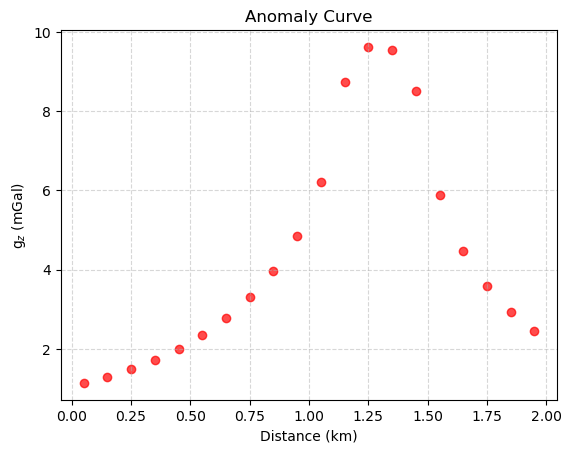

In [49]:
# Calculate the synthetic gravity anomaly curve
final_curve4 = automatic_gv_curve(densities, vecx, xq, z1, z2, t)
final_curve4

# PLOT THE ANOMALY CURVE

# Create a scatter plot of the calculated data
# plt.scatter(vecx, verificar, color='dodgerblue', marker='o', alpha=0.7)
plt.scatter(vecx, final_curve3, color='red', marker='o', alpha=0.7)

# Add axis labels and plot title
plt.xlabel('Distance (km)')
plt.ylabel('g$_z$ (mGal)')
plt.title('Anomaly Curve')

# Add gridlines to the plot
plt.grid(True, linestyle='--', alpha=0.5)

# Optional: Set custom axis limits
# plt.xlim(-0.25, 1.2)  # x-axis range
# plt.ylim(-0.5, 1)     # y-axis range

# Optional: Add noise level annotation
# plt.text(-10, 14, 'Noise: 6%', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))

# Optional: Add legend
# plt.legend(loc='upper center')

# Show the plot
plt.show()


#### 105 Degrees

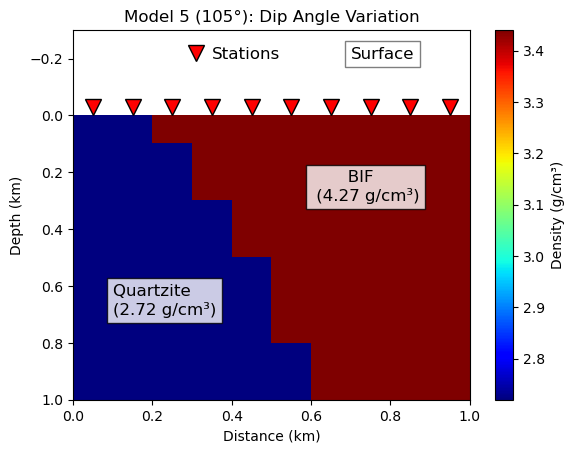

In [50]:
# 10x10 Density Grid

densities = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0]
])

# Initial density model (in g/cm³)
model_densities= np.array([
    [2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44]
])


# PLOTTING THE MODEL

# Display the 2D density distribution
plt.imshow(model_densities, extent=[0, 1, 1, 0], aspect='auto', cmap='jet')

# Adjust vertical scale
plt.ylim((1, -0.3))

# Plot station markers (red inverted triangles)
vecxx = np.array([0.05, 0.15, 0.25, 0.35, 0.45, 0.55, 0.65, 0.75, 0.85, 0.95])
vecyy = np.zeros_like(vecxx) - 0.03
plt.plot(vecxx, vecyy, "v", markersize=12, color='red', markeredgecolor='black')

# Add labels and annotations
plt.text(0.7, -0.2, 'Surface', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))
plt.text(0.35, -0.2, 'Stations', fontsize=12)
plt.plot(0.31, -0.22, "v", markersize=11, color='red', markeredgecolor='black')
plt.text(0.1, 0.7, 'Quartzite \n(2.72 g/cm³)', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))
plt.text(0.6, 0.30, '       BIF \n (4.27 g/cm³)', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))

# Add colorbar and axis labels
plt.colorbar(label='Density (g/cm³)')
plt.xlabel('Distance (km)')
plt.ylabel('Depth (km)')
plt.title('Model 5 (105°): Dip Angle Variation')

# Save the figure
# plt.savefig("DAV-5.png", facecolor='w', bbox_inches="tight", transparent=False, dpi=300)

# Show the plot
plt.show()


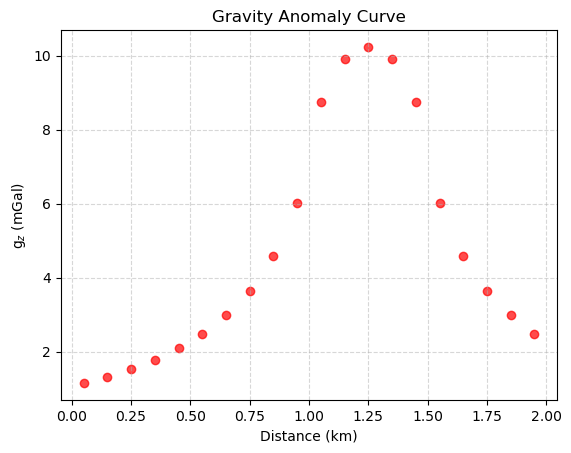

In [51]:
final_curve5 = automatic_gv_curve(densities, vecx, xq, z1, z2, t)
final_curve5

# PLOTTING THE GRAVITY ANOMALY CURVE

# Create a scatter plot for the calculated anomaly values
# plt.scatter(vecx, verificar,  color='dodgerblue', marker='o', alpha=0.7)
plt.scatter(vecx, final_curve4, color='red', marker='o', alpha=0.7)

# Add axis labels and a title to the graph
plt.xlabel('Distance (km)')
plt.ylabel('g$_z$ (mGal)')
plt.title('Gravity Anomaly Curve')

# Add a background grid
plt.grid(True, linestyle='--', alpha=0.5)

# Set the desired intervals for the x and y axes (optional)
# plt.xlim(-0.25, 1.2)  # X-axis range
# plt.ylim(-0.5, 1)     # Y-axis range

# Optional noise annotation
# plt.text(-10, 14, 'Noise: 6%', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))

# Show legend (if needed)
# plt.legend(loc='upper center')

# Display the plot
plt.show()


#### All curves

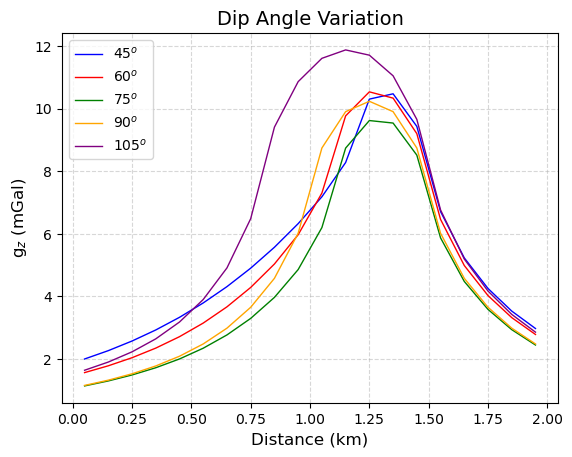

<Figure size 1000x600 with 0 Axes>

In [52]:
# Plotting the gravity anomaly curves for different dip angles
plt.plot(vecx, final_curve1, color='blue', linewidth=1, label='45$^o$')
plt.plot(vecx, final_curve2, color='red', linewidth=1, label='60$^o$')
plt.plot(vecx, final_curve3, color='green', linewidth=1, label='75$^o$')
plt.plot(vecx, final_curve4, color='orange', linewidth=1, label='90$^o$')
plt.plot(vecx, final_curve5, color='purple', linewidth=1, label='105$^o$')

# Add axis labels and title to the plot
plt.xlabel('Distance (km)', fontsize=12)
plt.ylabel('g$_z$ (mGal)', fontsize=12)
plt.title('Dip Angle Variation', fontsize=14)

# Add grid lines to the background
plt.grid(True, linestyle='--', alpha=0.5)

# Add a legend with custom position and font size
plt.legend(loc='upper left', fontsize=10)

# Set font sizes for axis ticks
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

# Save the figure (optional)
# plt.savefig("Dip_Angle_Variation.png", facecolor='w', bbox_inches="tight", transparent=True, dpi=300)

# Set the figure size
plt.figure(figsize=(10, 6))

# Adjust layout (optional)
# plt.tight_layout()

# Show the plot
plt.show()


In [80]:
final_curve3.max()

9.62101766253447

#### Horizontal Displacement of Contact

#### Model 1 (0.1 km)

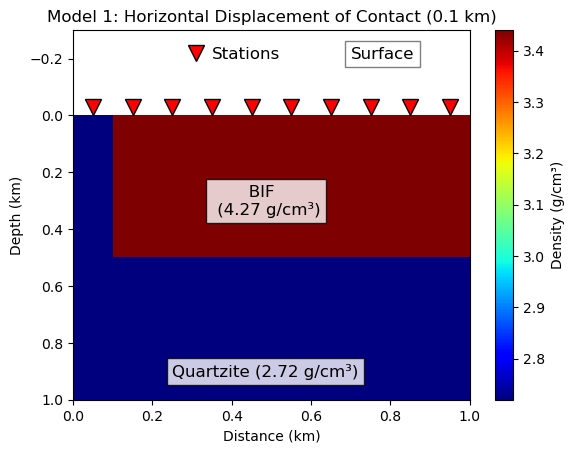

In [53]:
# 10x10 density matrix

densities  = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
])

# Initial density model
model_densities= np.array([
       [2.72, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44],
       [2.72, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44],
       [2.72, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44],
       [2.72, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44],
       [2.72, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44],
       [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72],
       [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72],
       [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72],
       [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72],
       [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72]
])


##### PLOTTING THE MODEL #####

# Plot the 2D model of density distribution
plt.imshow(model_densities, extent=[0, 1, 1, 0], aspect='auto', cmap='jet')
plt.ylim((1, -0.3))

# Add station markers as red inverted triangles
vecxx = np.array([0.05,0.15,0.25,0.35,0.45,0.55,0.65,0.75,0.85,0.95])
vecyy = np.zeros_like(vecxx) - 0.03
plt.plot(vecxx, vecyy, "v", markersize=12, color='red', markeredgecolor='black')

# Add text labels
plt.text(0.7, -0.2, 'Surface', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))
plt.text(0.35, -0.2, 'Stations', fontsize=12)
plt.plot(0.31, -0.22, "v", markersize=11, color='red', markeredgecolor='black')
plt.text(0.25, 0.92, 'Quartzite (2.72 g/cm³)', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))
plt.text(0.35, 0.35, '       BIF \n (4.27 g/cm³)', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))

# Add colorbar and axis labels
plt.colorbar(label='Density (g/cm³)')
plt.xlabel('Distance (km)')
plt.ylabel('Depth (km)')
plt.title('Model 1: Horizontal Displacement of Contact (0.1 km)')

# Save the figure
# plt.savefig("HDC-1.png", facecolor='w', bbox_inches="tight", transparent=False, dpi=300)

# Display the plot
plt.show()


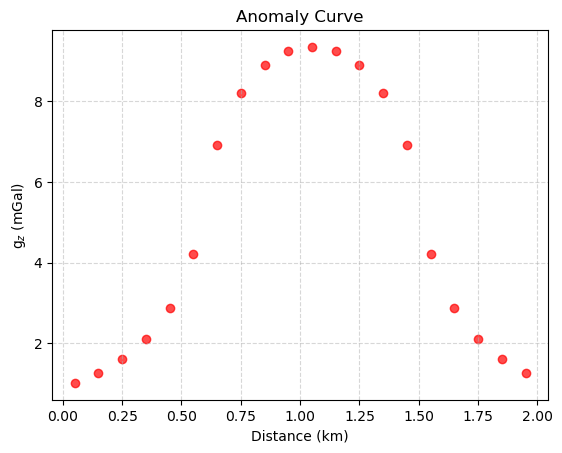

In [54]:
final_curve6 = automatic_gv_curve(densities, vecx, xq, z1, z2, t)
final_curve6

# PLOT THE GRAPH

# Create a scatter plot for the calculated data
# plt.scatter(vecx, verificar,  color='dodgerblue', marker='o', alpha=0.7)
plt.scatter(vecx, final_curve6, color='red', marker='o', alpha=0.7)

# Add axis labels and a title
plt.xlabel('Distance (km)')
plt.ylabel('g$_z$ (mGal)')
plt.title('Anomaly Curve')

# Add a grid to the background
plt.grid(True, linestyle='--', alpha=0.5)

# Set desired axis limits (optional)
# plt.xlim(-0.25, 1.2)  # X-axis range
# plt.ylim(-0.5, 1)     # Y-axis range

# Optional noise information
# plt.text(-10, 14, 'Noise: 6%', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))

# Display legend (if needed)
# plt.legend(loc='upper center')

# Display the plot
plt.show()


#### Model 2 (0.3 km)

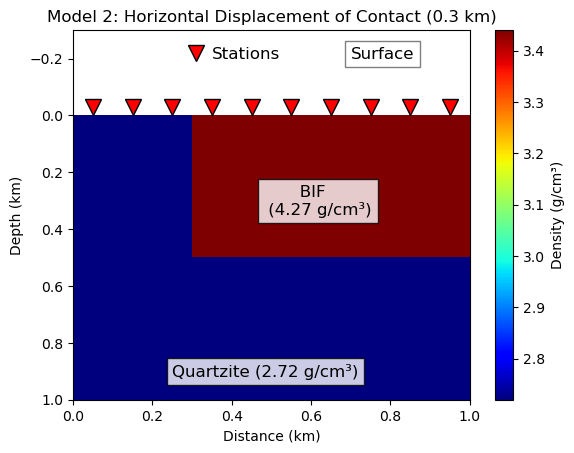

In [55]:
# 10x10 

densities = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
])

model_densities= np.array([
    [2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72]
])

# Clay - 2.21 g/cm³
# Limestone - 2.55 g/cm³
# Sandstone - 2.00 g/cm³
# Conglomerate - 2.50 g/cm³
# Metamorphic - 2.74 g/cm³

##### PLOTTING THE MODEL

# Reverse the Pastel1 color map (optional)
# pastel_reversed = plt.get_cmap('Pastel1').reversed()

# Plot the 2D model with different density layers
plt.imshow(model_densities, extent=[0, 1, 1, 0], aspect='auto', cmap='jet')
# , cmap=pastel_reversed

# Adjust Y-axis limits and add annotation
plt.ylim((1, -0.3))

# Add inverted triangle markers for station positions
vecxx = np.array([0.05, 0.15, 0.25, 0.35, 0.45, 0.55, 0.65, 0.75, 0.85, 0.95])
vecyy = np.zeros_like(vecxx) - 0.03
plt.plot(vecxx, vecyy, "v", markersize=12, color='red', markeredgecolor='black')

plt.text(0.7, -0.2, 'Surface', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))
plt.text(0.35, -0.2, 'Stations', fontsize=12)
plt.plot(0.31, -0.22, "v", markersize=11, color='red', markeredgecolor='black')
plt.text(0.25, 0.92, 'Quartzite (2.72 g/cm³)', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))
plt.text(0.48, 0.35, '       BIF \n (4.27 g/cm³)', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))

plt.colorbar(label='Density (g/cm³)')
plt.xlabel('Distance (km)')
plt.ylabel('Depth (km)')
plt.title('Model 2: Horizontal Displacement of Contact (0.3 km)')

# plt.savefig("HDC-2.png", facecolor='w', bbox_inches="tight", transparent=False, dpi=300)

plt.show()


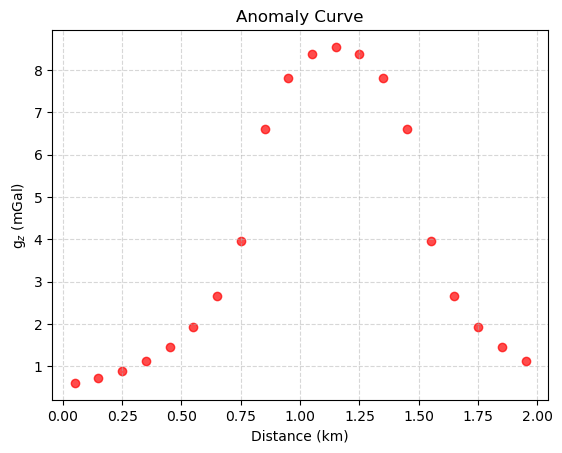

In [56]:
final_curve7 = automatic_gv_curve(densities, vecx, xq, z1, z2, t)
final_curve7

# PLOT THE GRAPH

# Create a scatter plot for the computed data
# plt.scatter(vecx, verificar,  color='dodgerblue', marker='o', alpha=0.7)
plt.scatter(vecx, final_curve7, color='red', marker='o', alpha=0.7)

# Add labels to axes and a title to the plot
plt.xlabel('Distance (km)')
plt.ylabel('g$_z$ (mGal)')
plt.title('Anomaly Curve')
# plt.ylim(0, 9.7)

# Add a background grid to the plot
plt.grid(True, linestyle='--', alpha=0.5)

# Define desired axis ranges (optional)
# plt.xlim(-0.25, 1.2)  # x-axis range
# plt.ylim(-0.5, 1)     # y-axis range

# plt.text(-10, 14, 'Noise: 6%', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))

# Show a legend (optional)
# plt.legend(loc='upper center')

# Display the plot
plt.show()


#### Model 3 (0.5 km)

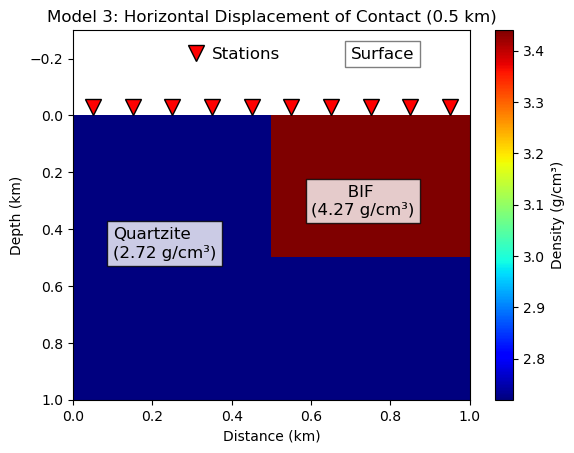

In [57]:
densities = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
])

# 10x10 

model_densities = np.array([
       [2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44],
       [2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44],
       [2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44],
       [2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44],
       [2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44],
       [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72],
       [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72],
       [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72],
       [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72],
       [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72]
])

# Clay - 2.21 g/cm³
# Limestone - 2.55 g/cm³
# Sandstone - 2.00 g/cm³
# Conglomerate - 2.50 g/cm³
# Metamorphic - 2.74 g/cm³

##### PLOTTING THE MODEL

# Plot the 2D model with different density layers
plt.imshow(model_densities, extent=[0, 1, 1, 0], aspect='auto', cmap='jet')

# Set Y-axis limits and add label
plt.ylim((1, -0.3))

# Add inverted triangle markers
vecxx = np.array([0.05, 0.15, 0.25, 0.35, 0.45, 0.55, 0.65, 0.75, 0.85, 0.95])
vecyy = np.zeros_like(vecxx) - 0.03
plt.plot(vecxx, vecyy, "v", markersize=12, color='red', markeredgecolor='black')

# Annotate surface and stations
plt.text(0.7, -0.2, 'Surface', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))
plt.text(0.35, -0.2, 'Stations', fontsize=12)
plt.plot(0.31, -0.22, "v", markersize=11, color='red', markeredgecolor='black')

# Annotate geological units
plt.text(0.1, 0.5, 'Quartzite\n(2.72 g/cm³)', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))
plt.text(0.6, 0.35, '       BIF\n(4.27 g/cm³)', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))

# Add colorbar and labels
plt.colorbar(label='Density (g/cm³)')
plt.xlabel('Distance (km)')
plt.ylabel('Depth (km)')
plt.title('Model 3: Horizontal Displacement of Contact (0.5 km)')

# Save and display
# plt.savefig("HDC-3.png", facecolor='w', bbox_inches="tight", transparent=False, dpi=300)
plt.show()


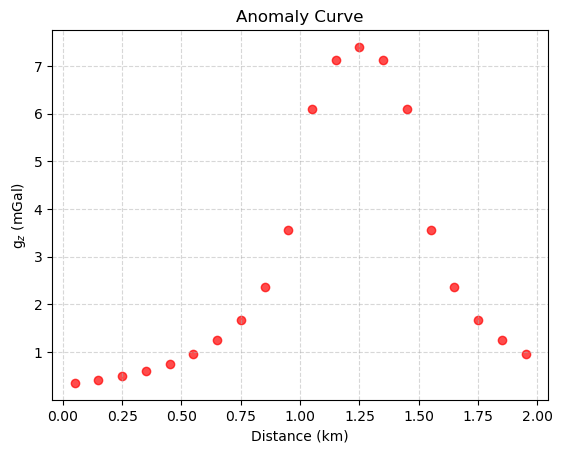

In [58]:
final_curve8 = automatic_gv_curve(densities, vecx, xq, z1, z2, t)
final_curve8

# PLOT THE GRAPH

# Create a scatter plot for the calculated data
# plt.scatter(vecx, verificar, color='dodgerblue', marker='o', alpha=0.7)
plt.scatter(vecx, final_curve8, color='red', marker='o', alpha=0.7)

# Add axis labels and a title to the graph
plt.xlabel('Distance (km)')
plt.ylabel('g$_z$ (mGal)')
plt.title('Anomaly Curve')

# Add a background grid to the plot
plt.grid(True, linestyle='--', alpha=0.5)

# Set the desired intervals for the x and y axes
# plt.xlim(-0.25, 1.2)  # X-axis range
# plt.ylim(-0.5, 1)     # Y-axis range

# Optionally add annotation (commented out)
# plt.text(-10, 14, 'Noise: 6%', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))

# Optionally show legend (commented out)
# plt.legend(loc='upper center')

# Display the graph
plt.show()


#### Model 4 (0.7 km)

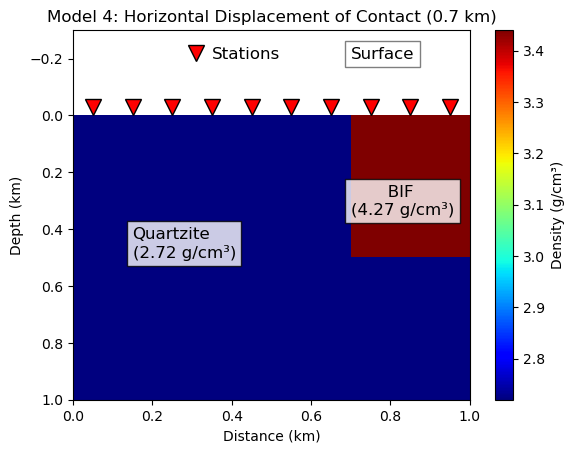

In [59]:
# 10x10 density model
densities = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
])

model_densities= np.array([
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72]
])

# Reference values for materials:
# Clay: 2.21 g/cm³
# Limestone: 2.55 g/cm³
# Sandstone: 2.00 g/cm³
# Conglomerate: 2.50 g/cm³
# Metamorphic: 2.74 g/cm³


# PLOTTING THE MODEL

# Plot the 2D density model with color representation
plt.imshow(model_densities, extent=[0, 1, 1, 0], aspect='auto', cmap='jet')
plt.ylim((1, -0.3))  # Reverse Y-axis for depth

# Add inverted triangle markers to represent surface stations
vecxx = np.array([0.05, 0.15, 0.25, 0.35, 0.45, 0.55, 0.65, 0.75, 0.85, 0.95])
vecyy = np.zeros_like(vecxx) - 0.03
plt.plot(vecxx, vecyy, "v", markersize=12, color='red', markeredgecolor='black')

# Add text labels to the plot
plt.text(0.7, -0.2, 'Surface', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))
plt.text(0.35, -0.2, 'Stations', fontsize=12)
plt.plot(0.31, -0.22, "v", markersize=11, color='red', markeredgecolor='black')
plt.text(0.15, 0.5, 'Quartzite\n(2.72 g/cm³)', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))
plt.text(0.7, 0.35, '       BIF\n(4.27 g/cm³)', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))

# Add colorbar and axis labels
plt.colorbar(label='Density (g/cm³)')
plt.xlabel('Distance (km)')
plt.ylabel('Depth (km)')
plt.title('Model 4: Horizontal Displacement of Contact (0.7 km)')

# Save and show the figure
# plt.savefig("HDC-4.png", facecolor='w', bbox_inches="tight", transparent=False, dpi=300)
plt.show()


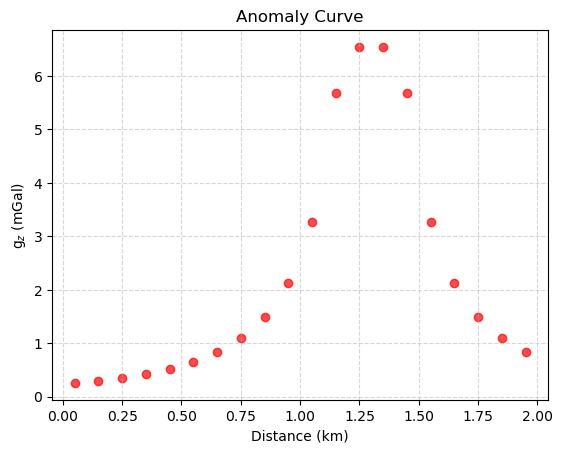

In [60]:
final_curve9 = automatic_gv_curve(densities, vecx, xq, z1, z2, t)
final_curve9

# PLOT THE GRAPH

# Create a scatter plot for the modeled data
# plt.scatter(vecx, verificar,  color='dodgerblue', marker='o', alpha=0.7)
plt.scatter(vecx, final_curve9, color='red', marker='o', alpha=0.7)

# Add labels and title
plt.xlabel('Distance (km)')
plt.ylabel('g$_z$ (mGal)')
plt.title('Anomaly Curve')

# Add grid to the background
plt.grid(True, linestyle='--', alpha=0.5)

# Set axis limits if necessary
# plt.xlim(-0.25, 1.2)  # X-axis range
# plt.ylim(-0.5, 1)     # Y-axis range
# plt.ylim(0, 9.6)

# Optional noise annotation
# plt.text(-10, 14, 'Noise: 6%', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))

# Optional legend
# plt.legend(loc='upper center')

# Display the plot
plt.show()


#### Model 5 (0.9 km)

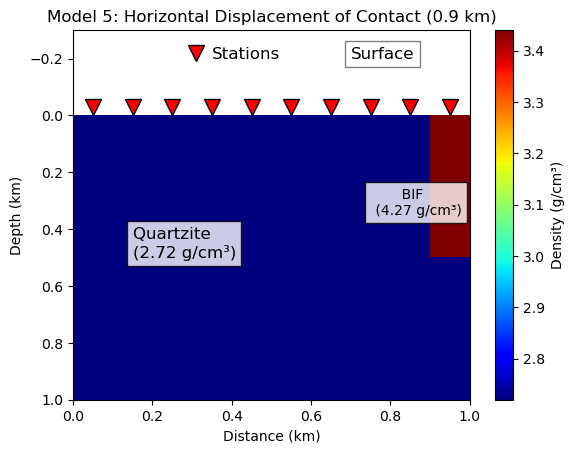

In [61]:
# 10x10 density grid
densities = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0]*20,
    [0.0]*20,
    [0.0]*20,
    [0.0]*20,
    [0.0]*20
])

# Initial density model for visualization (g/cm³)
model_densities= np.array([
    [2.72]*9 + [3.44],
    [2.72]*9 + [3.44],
    [2.72]*9 + [3.44],
    [2.72]*9 + [3.44],
    [2.72]*9 + [3.44],
    [2.72]*10,
    [2.72]*10,
    [2.72]*10,
    [2.72]*10,
    [2.72]*10
])

##### PLOTTING THE MODEL

# Plot the 2D density model
plt.imshow(model_densities, extent=[0, 1, 1, 0], aspect='auto', cmap='jet')
plt.ylim((1, -0.3))  # Flip y-axis for depth

# Add markers for observation stations
vecxx = np.array([0.05,0.15,0.25,0.35,0.45,0.55,0.65,0.75,0.85,0.95])
vecyy = np.zeros_like(vecxx) - 0.03
plt.plot(vecxx, vecyy, "v", markersize=12, color='red', markeredgecolor='black')

# Annotate elements on the plot
plt.text(0.7, -0.2, 'Surface', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))
plt.text(0.35, -0.2, 'Stations', fontsize=12)
plt.plot(0.31, -0.22, "v", markersize=11, color='red', markeredgecolor='black')
plt.text(0.15, 0.5, 'Quartzite \n(2.72 g/cm³)', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))
plt.text(0.75, 0.35, '       BIF \n (4.27 g/cm³)', fontsize=10, bbox=dict(facecolor='white', alpha=0.8))

# Add colorbar and axis labels
plt.colorbar(label='Density (g/cm³)')
plt.xlabel('Distance (km)')
plt.ylabel('Depth (km)')
plt.title('Model 5: Horizontal Displacement of Contact (0.9 km)')

# Save and show the figure
# plt.savefig("HDC-5.png", facecolor='w', bbox_inches="tight", transparent=False, dpi=300)
plt.show()


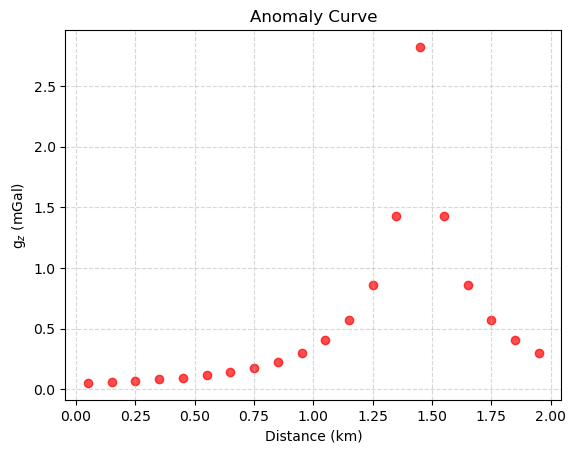

In [62]:
final_curve10 = automatic_gv_curve(densities, vecx, xq, z1, z2, t)
final_curve10

# PLOT THE GRAPH

# Creates a scatter plot for the calculated gravity anomaly
# plt.scatter(vecx, verificar,  color='dodgerblue', marker='o', alpha=0.7)
plt.scatter(vecx, final_curve10, color='red', marker='o', alpha=0.7)

# Add labels to axes and a title to the plot
plt.xlabel('Distance (km)')
plt.ylabel('g$_z$ (mGal)')
plt.title('Anomaly Curve')

# Add gridlines to the background of the plot
plt.grid(True, linestyle='--', alpha=0.5)

# Optional: Set axis limits if necessary
# plt.xlim(-0.25, 1.2)  # x-axis range
# plt.ylim(-0.5, 1)     # y-axis range

# Optional: Add text annotation
# plt.text(-10, 14, 'Noise: 6%', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))

# Optional: Display legend
# plt.legend(loc='upper center')

# Show the plot
plt.show()


#### All curves

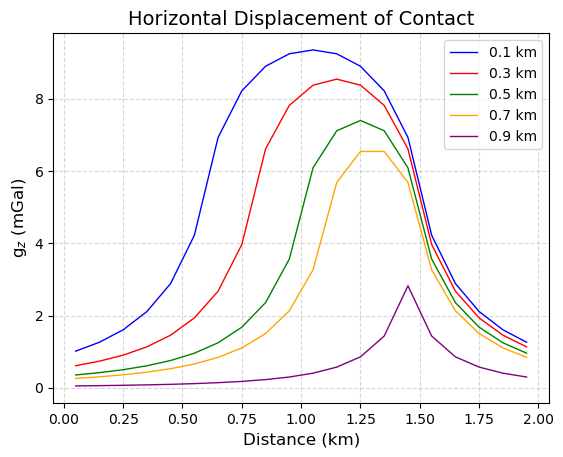

<Figure size 1000x600 with 0 Axes>

In [63]:
# Create line plots for the calculated anomaly curves
plt.plot(vecx, final_curve6, color='blue', linewidth=1, label='0.1 km')
plt.plot(vecx, final_curve7, color='red', linewidth=1, label='0.3 km')
plt.plot(vecx, final_curve8, color='green', linewidth=1, label='0.5 km')
plt.plot(vecx, final_curve9, color='orange', linewidth=1, label='0.7 km')
plt.plot(vecx, final_curve10, color='purple', linewidth=1, label='0.9 km')

# Add labels to the axes and a title to the plot
plt.xlabel('Distance (km)', fontsize=12)
plt.ylabel('g$_z$ (mGal)', fontsize=12)
plt.title('Horizontal Displacement of Contact', fontsize=14)

# Add grid lines to the background
plt.grid(True, linestyle='--', alpha=0.5)

# Configure and add the legend to the plot
plt.legend(loc='upper right', fontsize=10)

# Set font size for the axis tick labels
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

# Save the figure
# plt.savefig("Displacement_contact.png", facecolor='w', bbox_inches="tight", transparent=True, dpi=300)

# Set the figure size
plt.figure(figsize=(10, 6))

# Adjust the layout
plt.tight_layout()

# Show the plot
plt.show()


In [76]:
final_curve6.max()

9.351594711155125

In [77]:
final_curve10.max()

2.822852391167288

#### Vertical Displacement of Contact

#### Model 1 (0.1 km)

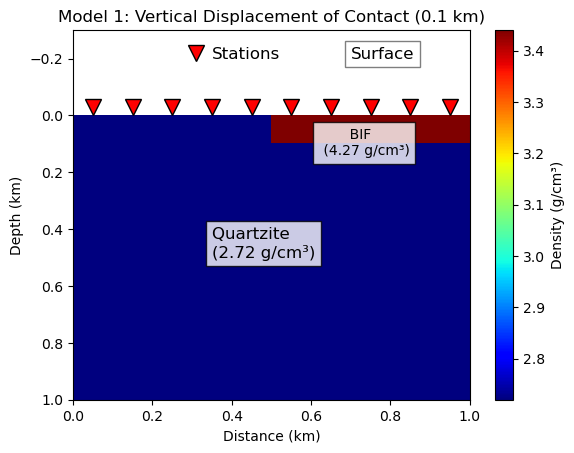

In [64]:
# 10x10 

densities = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
])

model_densities= np.array([
    [2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72]
])

# Density references (g/cm³)
# Clay - 2.21
# Limestone - 2.55
# Sandstone - 2.00
# Conglomerate - 2.50
# Metamorphic - 2.74


# ----- PLOTTING THE MODEL -----

# Plot the 2D model of density values
plt.imshow(model_densities, extent=[0, 1, 1, 0], aspect='auto', cmap='jet')
plt.ylim((1, -0.3))

# Add inverted triangle markers for stations
vecxx = np.array([0.05, 0.15, 0.25, 0.35, 0.45, 0.55, 0.65, 0.75, 0.85, 0.95])
vecyy = np.zeros_like(vecxx) - 0.03
plt.plot(vecxx, vecyy, "v", markersize=12, color='red', markeredgecolor='black')

# Add labels
plt.text(0.7, -0.2, 'Surface', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))
plt.text(0.35, -0.2, 'Stations', fontsize=12)
plt.plot(0.31, -0.22, "v", markersize=11, color='red', markeredgecolor='black')
plt.text(0.35, 0.5, 'Quartzite \n(2.72 g/cm³)', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))
plt.text(0.62, 0.14, '       BIF \n (4.27 g/cm³)', fontsize=10, bbox=dict(facecolor='white', alpha=0.8))

# Colorbar and axis labels
plt.colorbar(label='Density (g/cm³)')
plt.xlabel('Distance (km)')
plt.ylabel('Depth (km)')
plt.title('Model 1: Vertical Displacement of Contact (0.1 km)')

# Save or display the plot
# plt.savefig("VDC-1.png", facecolor='w', bbox_inches="tight", transparent=False, dpi=300)
plt.show()


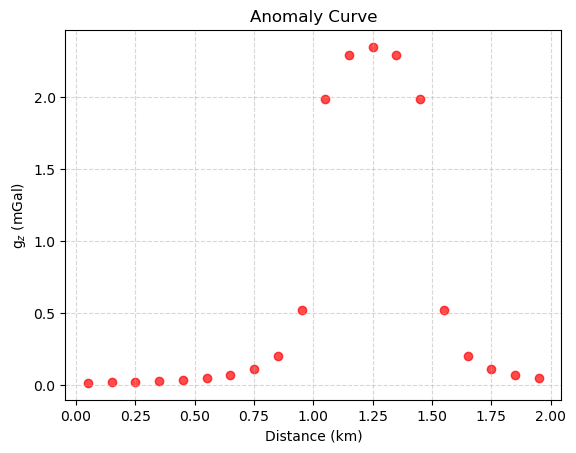

In [65]:
final_curve11 = automatic_gv_curve(densities, vecx, xq, z1, z2, t)
final_curve11

# PLOT THE GRAPH

# Create a scatter plot for the modeled data
# plt.scatter(vecx, verificar, color='dodgerblue', marker='o', alpha=0.7)
plt.scatter(vecx, final_curve11, color='red', marker='o', alpha=0.7)

# Add axis labels and a title to the plot
plt.xlabel('Distance (km)')
plt.ylabel('g$_z$ (mGal)')
plt.title('Anomaly Curve')

# Add a background grid to the plot
plt.grid(True, linestyle='--', alpha=0.5)

# Optional axis limits
# plt.xlim(-0.25, 1.2)  # x-axis range
# plt.ylim(-0.5, 1)     # y-axis range

# Optional annotation
# plt.text(-10, 14, 'Noise: 6%', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))

# Optional legend
# plt.legend(loc='upper center')

# Display the plot
plt.show()


#### Model 2 (0.3 km)

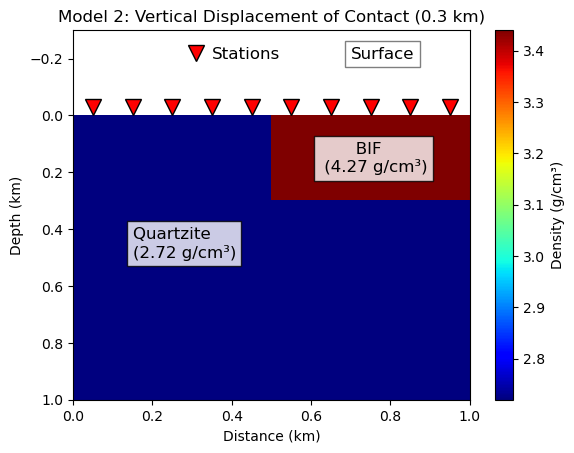

In [66]:
# 10x10 density grid

densities = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
])

model_densities= np.array([
    [2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 3.44, 3.44, 3.44, 3.44, 3.44],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72],
    [2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72, 2.72]
])


# PLOTTING THE MODEL

plt.imshow(model_densities, extent=[0, 1, 1, 0], aspect='auto', cmap='jet')
plt.ylim((1, -0.3))  # Reverse Y-axis

# Add station markers
vecxx = np.array([0.05, 0.15, 0.25, 0.35, 0.45, 0.55, 0.65, 0.75, 0.85, 0.95])
vecyy = np.zeros_like(vecxx) - 0.03
plt.plot(vecxx, vecyy, "v", markersize=12, color='red', markeredgecolor='black')

# Add annotations
plt.text(0.7, -0.2, 'Surface', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))
plt.text(0.35, -0.2, 'Stations', fontsize=12)
plt.plot(0.31, -0.22, "v", markersize=11, color='red', markeredgecolor='black')
plt.text(0.15, 0.5, 'Quartzite \n(2.72 g/cm³)', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))
plt.text(0.62, 0.2, '       BIF \n (4.27 g/cm³)', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))

# Add colorbar and labels
plt.colorbar(label='Density (g/cm³)')
plt.xlabel('Distance (km)')
plt.ylabel('Depth (km)')
plt.title('Model 2: Vertical Displacement of Contact (0.3 km)')

# plt.savefig("imagens/VDC-2.png", facecolor='w', bbox_inches="tight", transparent=False, dpi=300)
plt.show()


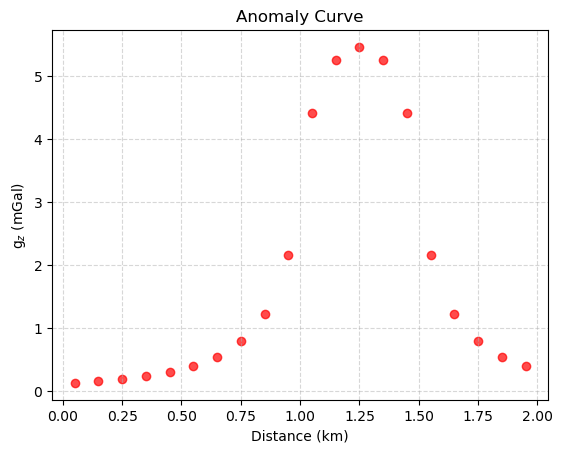

In [67]:
final_curve12 = automatic_gv_curve(densities, vecx, xq, z1, z2, t)
final_curve12

# PLOT THE GRAPH

# Creates a scatter plot for the calculated gravity anomaly
# plt.scatter(vecx, verificar, color='dodgerblue', marker='o', alpha=0.7)  # Uncomment if you want to compare with observed data
plt.scatter(vecx, final_curve12, color='red', marker='o', alpha=0.7)

# Add axis labels and plot title
plt.xlabel('Distance (km)')
plt.ylabel('g$_z$ (mGal)')
plt.title('Anomaly Curve')

# Add grid to the background
plt.grid(True, linestyle='--', alpha=0.5)

# Optional axis limits
# plt.xlim(-0.25, 1.2)
# plt.ylim(-0.5, 1)

# Optional noise text
# plt.text(-10, 14, 'Noise: 6%', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))

# Optional legend
# plt.legend(loc='upper center')

# Display the graph
plt.show()


#### Model 3 (0.5 km)

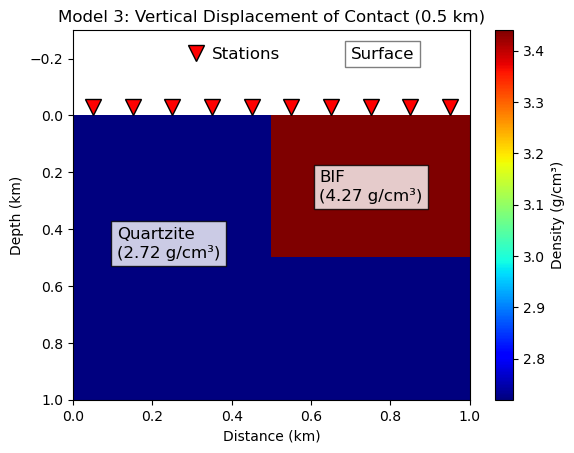

In [68]:
densities = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,  0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,  0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,  0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,  0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,  0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,  0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,  0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,  0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,  0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,  0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
])

initial_densities = np.array([
    [2.72]*5 + [3.44]*5,
    [2.72]*5 + [3.44]*5,
    [2.72]*5 + [3.44]*5,
    [2.72]*5 + [3.44]*5,
    [2.72]*5 + [3.44]*5,
    [2.72]*10,
    [2.72]*10,
    [2.72]*10,
    [2.72]*10,
    [2.72]*10
])

# Geological units (g/cm³):
# Clay = 2.21, Limestone = 2.55, Sandstone = 2.00
# Conglomerate = 2.50, Metamorphic = 2.74

### PLOTTING THE MODEL ###

plt.imshow(initial_densities, extent=[0, 1, 1, 0], aspect='auto', cmap='jet')

# Flip Y-axis
plt.ylim((1, -0.3))

# Add inverted triangle markers for stations
vecxx = np.linspace(0.05, 0.95, 10)
vecyy = np.full_like(vecxx, -0.03)
plt.plot(vecxx, vecyy, "v", markersize=12, color='red', markeredgecolor='black')

# Annotate elements
plt.text(0.7, -0.2, 'Surface', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))
plt.text(0.35, -0.2, 'Stations', fontsize=12)
plt.plot(0.31, -0.22, "v", markersize=11, color='red', markeredgecolor='black')
plt.text(0.11, 0.5, 'Quartzite\n(2.72 g/cm³)', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))
plt.text(0.62, 0.3, 'BIF\n(4.27 g/cm³)', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))

# Add colorbar and labels
plt.colorbar(label='Density (g/cm³)')
plt.xlabel('Distance (km)')
plt.ylabel('Depth (km)')
plt.title('Model 3: Vertical Displacement of Contact (0.5 km)')

# Save and show figure
# plt.savefig("images/VDC-3.png", facecolor='w', bbox_inches="tight", transparent=False, dpi=300)
plt.show()


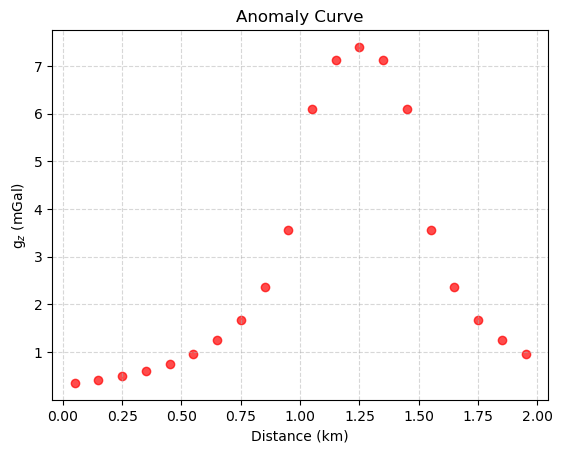

In [69]:
final_curve13 = automatic_gv_curve(densities, vecx, xq, z1, z2, t)
final_curve13

# PLOT THE GRAPH

# Create a scatter plot for the calculated data
# plt.scatter(vecx, verificar, color='dodgerblue', marker='o', alpha=0.7)
plt.scatter(vecx, final_curve13, color='red', marker='o', alpha=0.7)

# Add axis labels and a title to the graph
plt.xlabel('Distance (km)')
plt.ylabel('g$_z$ (mGal)')
plt.title('Anomaly Curve')

# Add a grid to the background
plt.grid(True, linestyle='--', alpha=0.5)

# Set custom axis ranges if needed
# plt.xlim(-0.25, 1.2)  # X-axis range
# plt.ylim(-0.5, 1)     # Y-axis range

# Add custom annotations if desired
# plt.text(-10, 14, 'Noise: 6%', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))

# Show legend if multiple curves are plotted
# plt.legend(loc='upper center')

# Display the plot
plt.show()


#### Model 4 (0.7 km)

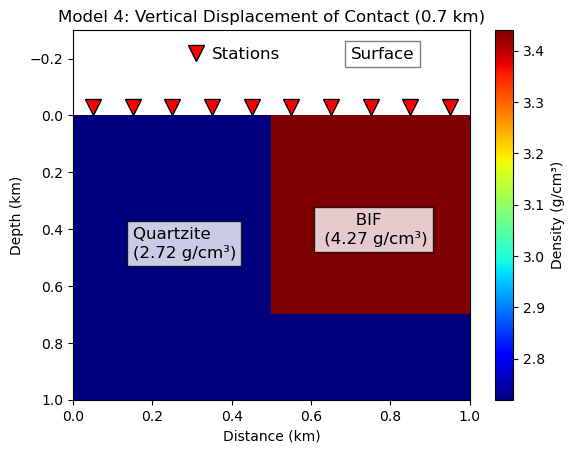

In [70]:
densities = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,  0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,  0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,  0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,  0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,  0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,  0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,  0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
])

# Initial model (10x10)
model_densities= np.array([
       [2.72,2.72,2.72,2.72,2.72,3.44,3.44,3.44,3.44,3.44],
       [2.72,2.72,2.72,2.72,2.72,3.44,3.44,3.44,3.44,3.44],
       [2.72,2.72,2.72,2.72,2.72,3.44,3.44,3.44,3.44,3.44],
       [2.72,2.72,2.72,2.72,2.72,3.44,3.44,3.44,3.44,3.44],
       [2.72,2.72,2.72,2.72,2.72,3.44,3.44,3.44,3.44,3.44],
       [2.72,2.72,2.72,2.72,2.72,3.44,3.44,3.44,3.44,3.44],
       [2.72,2.72,2.72,2.72,2.72,3.44,3.44,3.44,3.44,3.44],
       [2.72,2.72,2.72,2.72,2.72,2.72,2.72,2.72,2.72,2.72],
       [2.72,2.72,2.72,2.72,2.72,2.72,2.72,2.72,2.72,2.72],
       [2.72,2.72,2.72,2.72,2.72,2.72,2.72,2.72,2.72,2.72]])

# Clay - 2.21 g/cm³
# Limestone - 2.55 g/cm³
# Sandstone - 2.00 g/cm³
# Conglomerate - 2.50 g/cm³
# Metamorphic - 2.74 g/cm³


##### PLOTTING THE MODEL

# Plot the 2D model with different density layers
plt.imshow(model_densities, extent=[0, 1, 1, 0], aspect='auto', cmap='jet')

# Adjust vertical axis and add labels
plt.ylim((1, -0.3))

# Add markers for stations (inverted triangles)
vecxx = np.array([0.05,0.15,0.25,0.35,0.45,0.55,0.65,0.75,0.85,0.95])
vecyy = np.zeros_like(vecxx) - 0.03
plt.plot(vecxx, vecyy, "v", markersize=12, color='red', markeredgecolor='black')

# Annotations
plt.text(0.7, -0.2, 'Surface', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))
plt.text(0.35, -0.2, 'Stations', fontsize=12)
plt.plot(0.31, -0.22, "v", markersize=11, color='red', markeredgecolor='black')
plt.text(0.15, 0.5, 'Quartzite \n(2.72 g/cm³)', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))
plt.text(0.62, 0.45, '       BIF \n (4.27 g/cm³)', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))

# Colorbar and axis labels
plt.colorbar(label='Density (g/cm³)')
plt.xlabel('Distance (km)')
plt.ylabel('Depth (km)')
plt.title('Model 4: Vertical Displacement of Contact (0.7 km)')

# Save figure
# plt.savefig("VDC-4.png", facecolor='w', bbox_inches="tight", transparent=False, dpi=300)

# Show plot
plt.show()


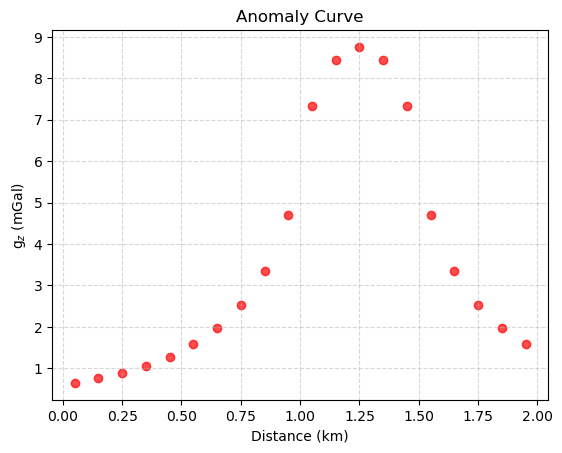

In [71]:
final_curve14 = automatic_gv_curve(densities, vecx, xq, z1, z2, t)
final_curve14

# PLOTTING THE GRAPH

# Create a scatter plot for the calculated gravity anomaly
# plt.scatter(vecx, verificar, color='dodgerblue', marker='o', alpha=0.7)
plt.scatter(vecx, final_curve14, color='red', marker='o', alpha=0.7)

# Add labels and a title to the plot
plt.xlabel('Distance (km)')
plt.ylabel('g$_z$ (mGal)')
plt.title('Anomaly Curve')

# Add grid to the background
plt.grid(True, linestyle='--', alpha=0.5)

# Optional: Set axis limits
# plt.xlim(-0.25, 1.2)
# plt.ylim(-0.5, 1)

# Optional: Add noise information or other annotations
# plt.text(-10, 14, 'Noise: 6%', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))

# Optional: Add legend
# plt.legend(loc='upper center')

# Show the plot
plt.show()


#### Model 5 (0.9 km)

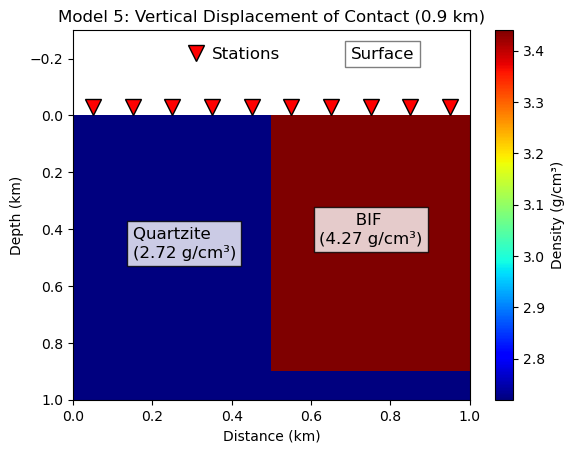

In [72]:
densities = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,  0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,  0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,  0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,  0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,  0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,  0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,  0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,  0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,  0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,  0.64, 0.64, 0.64, 0.64, 0.64, 0.0, 0.0, 0.0, 0.0, 0.0]
])

model_densities= np.array([
[2.72,2.72,2.72,2.72,2.72,3.44,3.44,3.44,3.44,3.44],
[2.72,2.72,2.72,2.72,2.72,3.44,3.44,3.44,3.44,3.44],
[2.72,2.72,2.72,2.72,2.72,3.44,3.44,3.44,3.44,3.44],
[2.72,2.72,2.72,2.72,2.72,3.44,3.44,3.44,3.44,3.44],
[2.72,2.72,2.72,2.72,2.72,3.44,3.44,3.44,3.44,3.44],
[2.72,2.72,2.72,2.72,2.72,3.44,3.44,3.44,3.44,3.44],
[2.72,2.72,2.72,2.72,2.72,3.44,3.44,3.44,3.44,3.44],
[2.72,2.72,2.72,2.72,2.72,3.44,3.44,3.44,3.44,3.44],
[2.72,2.72,2.72,2.72,2.72,3.44,3.44,3.44,3.44,3.44],
[2.72,2.72,2.72,2.72,2.72,2.72,2.72,2.72,2.72,2.72]
])


# Plotting the 2D density model
plt.imshow(model_densities, extent=[0, 1, 1, 0], aspect='auto', cmap='jet')
plt.ylim((1, -0.3))

# Add station markers
vecxx = np.array([0.05,0.15,0.25,0.35,0.45,0.55,0.65,0.75,0.85,0.95])
vecyy = np.zeros_like(vecxx) - 0.03
plt.plot(vecxx, vecyy, "v", markersize=12, color='red', markeredgecolor='black')

# Add labels and annotations
plt.text(0.7, -0.2, 'Surface', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))
plt.text(0.35, -0.2, 'Stations', fontsize=12)
plt.plot(0.31, -0.22, "v", markersize=11, color='red', markeredgecolor='black')
plt.text(0.15, 0.5, 'Quartzite \n(2.72 g/cm³)', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))
plt.text(0.62, 0.45, '       BIF \n(4.27 g/cm³)', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))

plt.colorbar(label='Density (g/cm³)')
plt.xlabel('Distance (km)')
plt.ylabel('Depth (km)')
plt.title('Model 5: Vertical Displacement of Contact (0.9 km)')

# plt.savefig("VDC-5.png", facecolor='w', bbox_inches="tight", transparent=False, dpi=300)
plt.show()


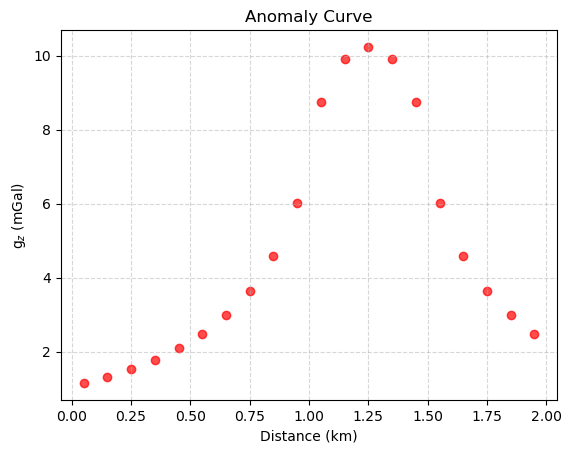

In [73]:
final_curve15 = automatic_gv_curve(densities, vecx, xq, z1, z2, t)
final_curve15

# PLOT THE GRAPH

# Create a scatter plot for the computed data
# plt.scatter(vecx, verificar, color='dodgerblue', marker='o', alpha=0.7)
plt.scatter(vecx, final_curve15, color='red', marker='o', alpha=0.7)

# Add axis labels and a title to the plot
plt.xlabel('Distance (km)')
plt.ylabel('g$_z$ (mGal)')
plt.title('Anomaly Curve')

# Add a grid to the background
plt.grid(True, linestyle='--', alpha=0.5)

# Define the desired axis ranges
# plt.xlim(-0.25, 1.2)  # X-axis range
# plt.ylim(-0.5, 1)     # Y-axis range

# Optional noise label
# plt.text(-10, 14, 'Noise: 6%', fontsize=12, bbox=dict(facecolor='white', alpha=0.5))

# Display a legend if needed
# plt.legend(loc='upper center')

# Show the plot
plt.show()


#### All curves

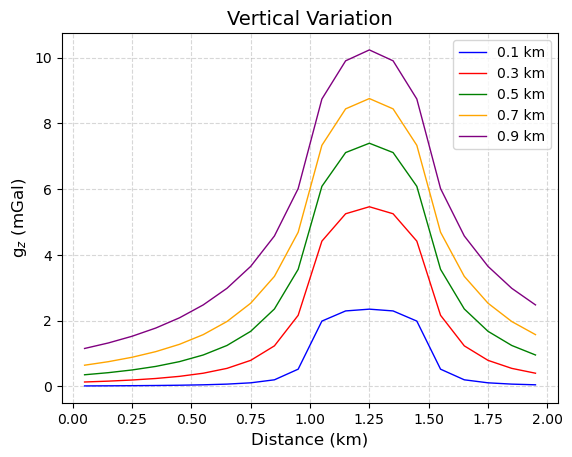

<Figure size 1000x600 with 0 Axes>

In [74]:
# PLOT THE GRAPH

# Create line plots for the computed data
plt.plot(vecx, final_curve11, color='blue', linewidth=1, label='0.1 km')
plt.plot(vecx, final_curve12, color='red', linewidth=1, label='0.3 km')
plt.plot(vecx, final_curve13, color='green', linewidth=1, label='0.5 km')
plt.plot(vecx, final_curve14, color='orange', linewidth=1, label='0.7 km')
plt.plot(vecx, final_curve15, color='purple', linewidth=1, label='0.9 km')

# Add axis labels and a title to the plot
plt.xlabel('Distance (km)', fontsize=12)
plt.ylabel('g$_z$ (mGal)', fontsize=12)
plt.title('Vertical Variation', fontsize=14)

# Add a background grid to the plot
plt.grid(True, linestyle='--', alpha=0.5)

# Define the legend style and add it to the plot
plt.legend(loc='upper right', fontsize=10)

# Set font size for the axis ticks
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

# Save the figure
# plt.savefig("Vertical_variation.png", facecolor='w', bbox_inches="tight", transparent=False, dpi=300)

# Set the figure size
plt.figure(figsize=(10, 6))

# Adjust the layout
plt.tight_layout()

# Display the plot
plt.show()


In [75]:
final_curve11.max()

2.3507460509100127

In [78]:
final_curve15.max()

10.236865456862544